In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Libraries loaded")

Libraries loaded


In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "energy_efficiency_data.csv"
print("Data file:", DATA_PATH)

Saving energy_efficiency_data (2).csv to energy_efficiency_data (2).csv
Data file: energy_efficiency_data (2).csv


In [ ]:
OUT_DIR = "eda_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

FEATURES = [
    "Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area",
    "Overall_Height", "Orientation", "Glazing_Area", "Glazing_Area_Distribution",
]
TARGETS = ["Heating_Load", "Cooling_Load"]   # Y1, Y2

def save_fig(name):
    path = os.path.join(OUT_DIR, name)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"saved -> {path}")

In [ ]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import joblib

CAT_COLS = ["Orientation", "Glazing_Area_Distribution"]

X = df[FEATURES]
y = df[TARGETS]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (614, 8) | Test: (154, 8)


In [ ]:
def add_features(X, engineer=True, drop=()):
    X = X.copy()
    if engineer:
        X["Wall_Surface_Ratio"] = X["Wall_Area"] / X["Surface_Area"]
        X["Glazing_x_Height"] = X["Glazing_Area"] * X["Overall_Height"]
    return X.drop(columns=list(drop))

def build_preprocessor(scale=True, onehot=True, engineer=True, drop=()):
    num_cols = [c for c in FEATURES if c not in CAT_COLS and c not in drop]
    if engineer:
        num_cols += ["Wall_Surface_Ratio", "Glazing_x_Height"]

    num_tf = StandardScaler() if scale else "passthrough"
    cat_tf = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else "passthrough"

    ct = ColumnTransformer([
        ("num", num_tf, num_cols),
        ("cat", cat_tf, CAT_COLS),
    ])
    return Pipeline([
        ("features", FunctionTransformer(add_features,
                                         kw_args={"engineer": engineer, "drop": drop})),
        ("transform", ct),
    ])

# نسخة للموديلات الخطية (scaling + onehot) ونسخة للـ trees (من غير scaling)
prep_linear = build_preprocessor(scale=True, onehot=True)
prep_tree   = build_preprocessor(scale=False, onehot=False)

Xtr_lin = prep_linear.fit_transform(X_train)   # fit على الـ train بس
Xte_lin = prep_linear.transform(X_test)
print("Linear-ready shape:", Xtr_lin.shape)

Linear-ready shape: (614, 18)


In [ ]:
import joblib
from src.preprocessing import build_preprocessor, FEATURES, TARGETS

prep_linear = build_preprocessor(scale=True, onehot=True)
prep_tree   = build_preprocessor(scale=False, onehot=False)
prep_linear.fit(X_train)
prep_tree.fit(X_train)

os.makedirs("processed", exist_ok=True)
X_train.assign(**y_train).to_csv("processed/train.csv", index=False)
X_test.assign(**y_test).to_csv("processed/test.csv", index=False)
joblib.dump(prep_linear, "processed/preprocessor_linear.joblib")
joblib.dump(prep_tree,   "processed/preprocessor_tree.joblib")

print(joblib.load("processed/preprocessor_linear.joblib").transform(X_test).shape)

(154, 18)


3️⃣ Modeling الأساسي (SageMaker Notebook)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

models = {
    "Linear Regression": (LinearRegression(), prep_linear),
    "Decision Tree":     (DecisionTreeRegressor(max_depth=8, random_state=42), prep_tree),
    "Random Forest":     (RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), prep_tree),
}

rows, preds = [], {}
for name, (model, prep) in models.items():
    model.fit(prep.transform(X_train), y_train)
    pred = model.predict(prep.transform(X_test))
    preds[name] = pred
    for i, tgt in enumerate(TARGETS):
        rows.append({
            "Model": name, "Target": tgt,
            "MAE":  mean_absolute_error(y_test[tgt], pred[:, i]),
            "RMSE": np.sqrt(mean_squared_error(y_test[tgt], pred[:, i])),
            "R²":   r2_score(y_test[tgt], pred[:, i]),
        })

results = pd.DataFrame(rows).round(4)
results.to_csv(os.path.join(OUT_DIR, "basic_models_results.csv"), index=False)
results

,Model,Target,MAE,RMSE,R²
0,Linear Regression,Heating_Load,1.8728,2.8002,0.9248
1,Linear Regression,Cooling_Load,2.1165,3.0471,0.8998
2,Decision Tree,Heating_Load,0.4071,0.5873,0.9967
3,Decision Tree,Cooling_Load,1.3253,2.2609,0.9448
4,Random Forest,Heating_Load,0.3446,0.4919,0.9977
5,Random Forest,Cooling_Load,1.1659,1.9043,0.9609


In [ ]:
cv_rows = []
for name, (model, prep) in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    for tgt in TARGETS:
        s = cross_val_score(pipe, X_train, y_train[tgt], cv=5, scoring="r2")
        cv_rows.append({"Model": name, "Target": tgt,
                        "CV R² mean": s.mean().round(4), "CV R² std": s.std().round(4)})
pd.DataFrame(cv_rows)

,Model,Target,CV R² mean,CV R² std
0,Linear Regression,Heating_Load,0.9275,0.0079
1,Linear Regression,Cooling_Load,0.8890,0.0124
2,Decision Tree,Heating_Load,0.9970,0.0003
3,Decision Tree,Cooling_Load,0.9595,0.0057
4,Random Forest,Heating_Load,0.9974,0.0005
5,Random Forest,Cooling_Load,0.9686,0.0052


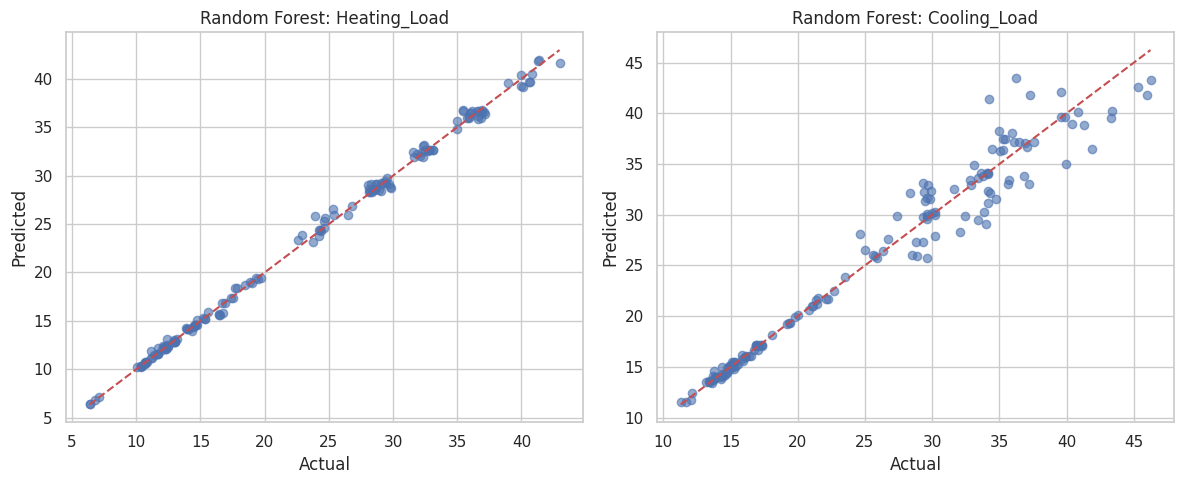

saved -> eda_outputs/08_actual_vs_pred.png


In [ ]:
best = "Random Forest"
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, (ax, tgt) in enumerate(zip(axes, TARGETS)):
    ax.scatter(y_test[tgt], preds[best][:, i], alpha=0.6)
    lims = [y_test[tgt].min(), y_test[tgt].max()]
    ax.plot(lims, lims, "r--")
    ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.set_title(f"{best}: {tgt}")
save_fig("08_actual_vs_pred.png")

os.makedirs("models", exist_ok=True)
for name, (model, prep) in models.items():
    joblib.dump(model, f"models/{name.replace(' ', '_').lower()}.joblib")